# Təsnifat Modelləri (Classification Models)

Bu notebookda bank sahəsində ən kritik biznes problemlərindən biri olan **Müştərilərin Bankı Tərk Etməsi (Customer Churn / Subscription)** məsələsi maşın öyrənməsinin (Machine Learning) **Supervised Classification (Nəzarətli Təsnifat)** alqoritmləri ilə hərtərəfli analiz edilir və modelləşdirilir.

---

### 1. Təsnifat Məsələsinin Mahiyyəti və Biznes Konteksti
Supervised Learning çərçivəsində təsnifat məsələlərində məqsəd giriş əlamətləri vektoruna ($\mathbf{x} = [x_1, x_2, \dots, x_p]$) əsasən hədəf dəyişəninin diskret sinif etiketini ($y \in \{0, 1\}$) proqnozlaşdırmaqdır.
* **$y = 0$ (Mənfi Sinif / Negative):** Müştəri bank xidmətində qalır (və ya depozit təklifini qəbul etmir).
* **$y = 1$ (Müsbət Sinif / Positive / Churn):** Müştəri bankı tərk edir (və ya kampaniyada təklifi qəbul edir).

> **Biznes Mənası:** Yeni müştəri cəlb etmək (Customer Acquisition) mövcud müştərini saxlamaqdan (Customer Retention) **5-7 dəfə daha baha başa gəlir**. Əgər bank sistemi müştərinin getmək ehtimalını qabaqcadan dəqiq proqnozlaşdıra bilsə, marketinq və CRM departamenti həmin müştəriyə fərdi loyallıq təklifi və ya xüsusi faiz dərəcəsi təqdim edərək itkini minimuma endirə bilər.

---

### 2. Balanssız Data (Imbalanced Data) və Qiymətləndirmə Metrikaları
Bank churn məlumatlarında siniflərin paylanması adətən kəskin qeyri-bərabər (imbalanced) olur (məsələn, ~88% loyal, ~12% churn). Belə vəziyyətlərdə sadə **Accuracy (Ümumi Dəqiqlik)** metrikasından istifadə etmək **kobud metodoloji səhvdir**:
* Bütün müştərilərə "0" (getməyəcək) deyən primitiv bir model **88.3% Accuracy** toplayacaq, lakin gedən müştərilərin (Class 1) **0%-ni** aşkar edəcək!

Buna görə də modelin effektivliyi aşağıdakı əsas metrikalarla ölçülür:

$$\text{Confusion Matrix (Qarışıqlıq Matrisi):} \quad \begin{pmatrix} TN & FP \\ FN & TP \end{pmatrix}$$

1. **Accuracy (Ümumi Dəqiqlik):**
   $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
   Bütün proqnozlar içərisində düzgün tapılanların payı.

2. **Precision (Həssaslıq / Dəqiqlik):**
   $$\text{Precision} = \frac{TP}{TP + FP}$$
   Modelin "Bu müştəri tərk edəcək" dediyi şəxslərin neçə faizinin həqiqətən getdiyini göstərir. Yüksək Precision lazımsız marketinq xərclərini azaldır.

3. **Recall / Sensitivity (Tutma Dərəcəsi):**
   $$\text{Recall} = \frac{TP}{TP + FN}$$
   Həqiqətən bankı tərk edən bütün müştərilərin neçə faizinin model tərəfindən aşkar edildiyini ölçür. Yüksək Recall itirilən müştəri sayını minimuma endirir.

4. **F1-Score (Harmonik Orta):**
   $$\text{F1} = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$
   Precision və Recall arasındakı kompromisi balanslaşdıran metrika. Dengesiz verilənlərdə əsas diqqət **Class 1 (Churn) F1-Score** göstəricisinə verilməlidir.

5. **ROC-AUC (Receiver Operating Characteristic - Area Under Curve):**
   Müxtəlif qərar hədlərində (threshold) $TPR$ (True Positive Rate) və $FPR$ (False Positive Rate) arasındakı əlaqəni ümumiləşdirir. $1.0$ ideal ayırdetmə qabiliyyətini, $0.5$ isə təsadüfi proqnozu göstərir.

---

### 3. Tədqiq Edilən 8 Təsnifat Modeli
Bu dəftərdə müasir maşın öyrənməsinin ən aparıcı 8 alqoritmi eyni şərtlər altında müqayisə edilir:
1. **GLM (Logistic Regression)** — Xətti ehtimal modeli və baza (baseline) arxitekturası.
2. **K-Nearest Neighbors (KNN)** — Məsafəyə əsaslanan qeyri-parametrik alqoritm.
3. **Naive Bayes (GaussianNB)** — Bayes ehtimal teoreminə əsaslanan sadəlövh müstəqillik modeli.
4. **Support Vector Machine (SVC)** — Marjanı maksimallaşdıran və RBF kernel ilə qeyri-xətti fəzaya proyeksiya edən model.
5. **Decision Tree (CART)** — İerarxik qaydalar ağacı və Gini kriteriyası.
6. **Random Forest** — Bootstrap Aggregation (Bagging) və əlamətlərin təsadüfi seçilməsi ilə dispersiyanı azaldan güclü ansambl.
7. **XGBoost (eXtreme Gradient Boosting)** — İkinci tərtib Teylor approksimasiyası və requlyarizasiyalı qradiyent gücləndirmə.
8. **LightGBM** — Microsoft tərəfindən yaradılmış yüksək sürətli, histogram və yarpaq-yönümlü (leaf-wise) ən müasir qradiyent gücləndirmə alqoritmi.

## 1. Lazımi Kitabxanaların Yüklənməsi

In [3]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

# Scikit-learn: Datanın bölünməsi, boru xətləri və miqyaslama
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Təsnifat Alqoritmi
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Qiymətləndirmə metrikaları
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix, classification_report
)

# Vizual stillər
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10

## 2. Datanın Yüklənməsi və İlkin Təmizlənmə

`churn.csv` faylı bank müştərilərinin demoqrafik, maliyyə və əvvəlki marketinq əlaqələri üzrə məlumatlarını ehtiva edir.

> [!WARNING]
> **Kritik Metodoloji Düzəliş (Data Leakage Fix):**
> İlkin koda baxdıqda `exclude = ['id']` dəyişəni yaradılsa da, model üçün əlamətlər ayrılarkən `X = data.drop(columns=[target])` yazılmış və `id` sütunu modelə daxil edilmişdi!
> `id` sütunu hər bir müştərinin verilənlər bazasındakı texniki sıra nömrəsidir. Modelə daxil edildikdə saxta asılılıqlar və ifrat öyrənmə (overfitting) yaradır. Bu səbəbdən `id` sütunu həm ədədi əlamətlərdən, həm də giriş matrisindən (`X`) tamamilə xaric edilməlidir.

In [4]:
data = pd.read_csv('churn.csv')
print(f"Dataset ölçüsü: {data.shape[0]:,} sətir, {data.shape[1]} sütun\n")
data.head()

Dataset ölçüsü: 45,211 sətir, 18 sütun



,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,1,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,2,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,3,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,4,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,5,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:
data.info()

print("\n=== Çatışmayan Dəyərlərin (NaN) Sayı ===")
print(data.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         45211 non-null  int64 
 1   age        45211 non-null  int64 
 2   job        45211 non-null  object
 3   marital    45211 non-null  object
 4   education  45211 non-null  object
 5   default    45211 non-null  object
 6   balance    45211 non-null  int64 
 7   housing    45211 non-null  object
 8   loan       45211 non-null  object
 9   contact    45211 non-null  object
 10  day        45211 non-null  int64 
 11  month      45211 non-null  object
 12  duration   45211 non-null  int64 
 13  campaign   45211 non-null  int64 
 14  pdays      45211 non-null  int64 
 15  previous   45211 non-null  int64 
 16  poutcome   45211 non-null  object
 17  y          45211 non-null  object
dtypes: int64(8), object(10)
memory usage: 6.2+ MB

=== Çatışmayan Dəyərlərin (NaN) Sayı ===
id           0
age

In [6]:
# Hədəf dəyişənin binar integer (0 və 1) formatına çevrilməsi
data["y"] = data["y"].replace({"yes": 1, "no": 0}).astype(int)

# Siniflərin paylanması (İmbalance analizi)
class_counts = data["y"].value_counts()
class_pct = data["y"].value_counts(normalize=True) * 100

print("Hədəf dəyişəninin ('y') paylanması:")
print(f"0 (Qalan müştərilər - No):  {class_counts[0]:,} nəfər ({class_pct[0]:.2f}%)")
print(f"1 (Tərk edən müştərilər - Yes): {class_counts[1]:,} nəfər ({class_pct[1]:.2f}%)")
print(f"\nDengesizlik Nisbəti (Imbalance Ratio): 1 Churn müştəriyə ~{class_counts[0]/class_counts[1]:.1f} sadiq müştəri düşür.")

Hədəf dəyişəninin ('y') paylanması:
0 (Qalan müştərilər - No):  39,922 nəfər (88.30%)
1 (Tərk edən müştərilər - Yes): 5,289 nəfər (11.70%)

Dengesizlik Nisbəti (Imbalance Ratio): 1 Churn müştəriyə ~7.5 sadiq müştəri düşür.


## 3. Asılı və Sərbəst Dəyişənlərin Ayrılması və Train / Test Bölünməsi

* **Sərbəst dəyişənlər ($X$):** Hədəf sütun (`y`) və sətir identifikatoru (`id`) tam xaric edilir.
* **Asılı dəyişən ($y$):** Müştərinin tərk etmə statusu ($0$ və ya $1$).
* **Stratified Split:** Siniflərin kəskin qeyri-bərabərliyini nəzərə alaraq `stratify=y` parametri tətbiq edilir. Bu parametr təlim (80%) və test (20%) alt-dəstlərində Churn nisbətinin (11.7%) dəqiqliklə eyni qalmasını təmin edir.

In [7]:
target = 'y'
exclude = ['id']

# 'id' sütununun etibarlı şəkildə kənarlaşdırılması
drop_cols = [c for c in [target] + exclude if c in data.columns]
X = data.drop(columns=drop_cols)
y = data[target]

# 80% Train, 20% Test olaraq stratifikasiyalı bölünmə
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123, stratify=y
)

print(f"Təlim matrisi (X_train): {X_train.shape[0]:,} sətir, {X_train.shape[1]} əlamət")
print(f"Test matrisi  (X_test):  {X_test.shape[0]:,} sətir, {X_test.shape[1]} əlamət")
print(f"'id' sütunu X matrisində varmı?: {'id' in X.columns} (Leakage tam aradan qaldırıldı!)")
print(f"\nTrain dəstində Churn nisbəti: {y_train.mean():.4f} ({y_train.mean()*100:.2f}%)")
print(f"Test dəstində Churn nisbəti:  {y_test.mean():.4f} ({y_test.mean()*100:.2f}%)")

Təlim matrisi (X_train): 36,168 sətir, 16 əlamət
Test matrisi  (X_test):  9,043 sətir, 16 əlamət
'id' sütunu X matrisində varmı?: False (Leakage tam aradan qaldırıldı!)

Train dəstində Churn nisbəti: 0.1170 (11.70%)
Test dəstində Churn nisbəti:  0.1170 (11.70%)


## 4. Əlamətlərin İlkin Emalı (Feature Preprocessing Pipelines)

Model ailələrinin riyazi fərziyyələri bir-birindən kəskin fərqlənir:
1. **Məsafə və Qradiyent Əsaslı Modellər (GLM, KNN, SVM, Naive Bayes):**
   * Ədədi əlamətlərin miqyası nəticələrə birbaşa təsir edir. Məsələn, `balance` parametri minlərlə manat, `age` isə onluq rəqəmlərlə ölçülür. Miqyaslama (`StandardScaler`) aparılmadıqda KNN və SVM yalnız böyük rəqəmləri "görür".
   * Buna görə `preprocess_scaled` boru xəttində ədədi sütunlar $Z = \frac{X - \mu}{\sigma}$ standartlaşdırılır, kateqorial sütunlar isə `OneHotEncoder` ilə kodlaşdırılır.
2. **Qərar Ağacı və Ansambl Modelləri (Decision Tree, Random Forest, XGBoost, LightGBM):**
   * Ağaclar hər bir düyündə tək bir dəyişəni digərlərindən asılı olmayaraq böldüyü üçün (monoton transformasiyalara qarşı invariantlıq) ədədi dəyişənlərin miqyaslanmasına ehtiyac duymur (`passthrough`).
   * Buna görə `preprocess_basic` boru xəttində ədədi sütunlar dəyişdirilmədən ötürülür, kateqoriallar isə binarlaşdırılır.

In [8]:
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

print(f"Ədədi dəyişənlər ({len(num_cols)} ədəd):", num_cols)
print(f"Kateqorial dəyişənlər ({len(cat_cols)} ədəd):", cat_cols)

# 1. Ağac modelləri üçün əsas boru xətti (ədədilər dəyişmir, kateqoriallar One-Hot)
preprocess_basic = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ],
    remainder="drop",
)

# 2. Xətti və məsafə modelləri üçün miqyaslanmış boru xətti (StandardScaler + One-Hot)
preprocess_scaled = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ],
    remainder="drop",
)

Ədədi dəyişənlər (7 ədəd): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Kateqorial dəyişənlər (9 ədəd): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 5. Vahid Qiymətləndirmə Mühərriki (`eval_clf`)

Dengesiz təsnifat problemlərində modelləri obyektiv qiymətləndirmək üçün universal funksiya tərtib olunur:
* **Overfitting Diaqnostikası:** Model həm `Train`, həm də `Test` dəstlərində qiymətləndirilir (`train_roc_auc` vs `test_roc_auc`). Əgər Train skoru 0.99, Test skoru isə 0.80 olarsa, modelin ifrat öyrəndiyi dərhal aşkarlanır.
* **Class 1 (Churn) Hədəfi:** Ümumi çəkili (weighted) ortalama əvəzinə bank üçün həyati əhəmiyyət kəsb edən **Class 1 Precision, Recall və F1-Score** metrikaları izlənir.
* **ROC Əyrisi Məlumatlarının Toplanması:** Sonrakı müqayisəli vizuallaşdırma üçün hər bir modelin FPR (False Positive Rate) və TPR (True Positive Rate) nöqtələri saxlanılır.

In [9]:
results = []
roc_curves_data = {}

def eval_clf(name, model, X_train, y_train, X_test, y_test):
    t0 = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - t0
    
    # Proqnozlar (Sinif etiketləri)
    y_pred_test = model.predict(X_test)
    y_pred_train = model.predict(X_train)
    
    # Əsas metrikalar (Xüsusilə Churn / Class 1 üçün)
    test_acc = accuracy_score(y_test, y_pred_test)
    test_prec_1 = precision_score(y_test, y_pred_test, pos_label=1, zero_division=0)
    test_rec_1 = recall_score(y_test, y_pred_test, pos_label=1, zero_division=0)
    test_f1_1 = f1_score(y_test, y_pred_test, pos_label=1, zero_division=0)
    test_f1_weighted = f1_score(y_test, y_pred_test, average="weighted")
    
    # Ehtimal və ROC-AUC hesablanması
    test_roc_auc = np.nan
    train_roc_auc = np.nan
    
    if hasattr(model, "predict_proba"):
        proba_test = model.predict_proba(X_test)[:, 1]
        proba_train = model.predict_proba(X_train)[:, 1]
        test_roc_auc = roc_auc_score(y_test, proba_test)
        train_roc_auc = roc_auc_score(y_train, proba_train)
        fpr, tpr, _ = roc_curve(y_test, proba_test)
        roc_curves_data[name] = (fpr, tpr, test_roc_auc)
    elif hasattr(model, "decision_function"):
        dec_test = model.decision_function(X_test)
        dec_train = model.decision_function(X_train)
        test_roc_auc = roc_auc_score(y_test, dec_test)
        train_roc_auc = roc_auc_score(y_train, dec_train)
        fpr, tpr, _ = roc_curve(y_test, dec_test)
        roc_curves_data[name] = (fpr, tpr, test_roc_auc)
        
    metrics = {
        "model": name,
        "test_roc_auc": round(test_roc_auc, 4),
        "test_f1_churn": round(test_f1_1, 4),
        "test_recall_churn": round(test_rec_1, 4),
        "test_prec_churn": round(test_prec_1, 4),
        "test_accuracy": round(test_acc, 4),
        "test_f1_weighted": round(test_f1_weighted, 4),
        "train_roc_auc": round(train_roc_auc, 4),
        "overfit_gap_auc": round(train_roc_auc - test_roc_auc, 4) if not np.isnan(train_roc_auc) else np.nan,
        "fit_time_sec": round(fit_time, 2)
    }
    
    print(f"=== [{name}] ===")
    print(f"Test ROC-AUC:      {test_roc_auc:.4f}  |  Train ROC-AUC: {train_roc_auc:.4f}  (Fərq: {metrics['overfit_gap_auc']:+.4f})")
    print(f"Churn F1-Score:    {test_f1_1:.4f}  |  Weighted F1:   {test_f1_weighted:.4f}")
    print(f"Churn Recall:      {test_rec_1:.4f}  |  Churn Prec:    {test_prec_1:.4f}")
    print(f"Test Accuracy:     {test_acc:.4f}  |  Təlim Müddəti: {fit_time:.2f} san\n")
    
    return metrics

## 6. Model 1: GLM (Generalised Linear Model — Logistic Regression)

### Nəzəri Əsasları və Riyazi İzahı:
Logistik Reqressiya asılı dəyişənin binar ($y \in \{0, 1\}$) olduğu hallarda hadisənin baş vermə ehtimalını modelləşdirən xətti təsnifat alqoritmidir.

Xətti reqressiyadan fərqli olaraq, burada asılı dəyişən birbaşa deyil, **Logit (Log-Odds)** funksiyası vasitəsilə xətti kombinasiyaya bərabər tutulur:
$$\ln\left(\frac{p}{1 - p}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p = \mathbf{x}^T \boldsymbol{\beta}$$

Ehtimalın ($p$) özü isə **Sigmoid (Logistik)** funksiyası vasitəsilə $[0, 1]$ intervalına sıxılır:
$$p = P(Y = 1 | \mathbf{x}) = \sigma(\mathbf{x}^T \boldsymbol{\beta}) = \frac{1}{1 + e^{-\mathbf{x}^T \boldsymbol{\beta}}}$$

### Əsas Xüsusiyyətləri:
* **İtgi Funksiyası (Loss Function):** Maksimal Həqiqətəoxşarlıq (Maximum Likelihood Estimation - MLE) və ya Binary Cross-Entropy (Log Loss).
* **Şəffaflıq və İzaholunma:** Əmsalların eksponenti ($e^{\beta_j}$) **Odds Ratio (Şans Nisbəti)** mənasını verir. Məsələn, $e^{\beta_j} = 1.25$ olarsa, həmin əlamətin 1 vahid artması müştərinin tərk etmə şansını 25% artırır.
* **Hiperparametrlər:** `C=1.0` (L2 requlyarizasiyasının tərs gücü $1/\lambda$), `max_iter=1000` (qradiyent enişinin konvergensiyası üçün kifayət qədər iterasiya).

In [10]:
glm_pipe = Pipeline([
    ("prep", preprocess_scaled),
    ("model", LogisticRegression(max_iter=1000, random_state=123))
])

results.append(eval_clf("GLM (Logistic)", glm_pipe, X_train, y_train, X_test, y_test))

=== [GLM (Logistic)] ===
Test ROC-AUC:      0.8997  |  Train ROC-AUC: 0.9101  (Fərq: +0.0103)
Churn F1-Score:    0.4382  |  Weighted F1:   0.8864
Churn Recall:      0.3299  |  Churn Prec:    0.6523
Test Accuracy:     0.9010  |  Təlim Müddəti: 0.27 san



## 7. Model 2: K-Nearest Neighbors (KNN — K-Ən Yaxın Qonşu)

### Nəzəri Əsasları və Riyazi İzahı:
KNN **qeyri-parametrik və tənbəl (lazy learning)** təsnifat alqoritmidir. Bu alqoritm təlim mərhələsində açıq riyazi funksiya öyrənmir, bütün təlim nöqtələrini yaddaşda saxlayır.

Yeni bir $\mathbf{x}$ test nöqtəsi daxil olduqda:
1. Çoxölçülü fəzada ona ən yaxın olan $k$ sayda təlim müşahidəsi Evklid məsafəsi ilə tapılır:
   $$d(\mathbf{x}, \mathbf{x}^{(i)}) = \sqrt{\sum_{j=1}^p (x_j - x_j^{(i)})^2}$$
2. Həmin $k$ qonşu arasında səsvermə keçirilir və 1 sinfinin payı ehtimal kimi qəbul edilir:
   $$\hat{P}(Y = 1 | \mathbf{x}) = \frac{1}{k} \sum_{i \in \mathcal{N}_k(\mathbf{x})} \mathbb{I}(y^{(i)} = 1)$$

### Əsas Xüsusiyyətləri və Niyə Miqyaslama Vacibdir:
* Əgər əlamətlər `StandardScaler` ilə standartlaşdırılmasa, minlərlə manatlıq `balance` fərqi onluq yaş (`age`) fərqini tamamilə ört-basdır edəcək.
* **Hiperparametr $k$:** Çox kiçik $k$ (məs. $k=1$) ifrat öyrənməyə və səs-küyə həssaslığa (high variance), çox böyük $k$ isə qərar sərhədinin həddindən artıq hamarlaşmasına (high bias) səbəb olur. Burada $k=25$ optimal balans yaradır.

In [11]:
knn_pipe = Pipeline([
    ("prep", preprocess_scaled),
    ("model", KNeighborsClassifier(n_neighbors=25, weights="uniform", n_jobs=-1))
])

results.append(eval_clf("KNN", knn_pipe, X_train, y_train, X_test, y_test))

=== [KNN] ===
Test ROC-AUC:      0.8885  |  Train ROC-AUC: 0.9342  (Fərq: +0.0457)
Churn F1-Score:    0.3857  |  Weighted F1:   0.8797
Churn Recall:      0.2703  |  Churn Prec:    0.6729
Test Accuracy:     0.8993  |  Təlim Müddəti: 0.07 san



## 8. Model 3: Naive Bayes (GaussianNB — Sadəlövh Bayes)

### Nəzəri Əsasları və Riyazi İzahı:
Naive Bayes modeli **Bayes Şərti Ehtimal Teoreminə** əsaslanır:
$$P(Y = c | \mathbf{x}) = \frac{P(Y = c) \cdot P(\mathbf{x} | Y = c)}{P(\mathbf{x})}$$

Burada "sadəlövh" (naive) adlanmasının səbəbi bütün əlamətlərin verilmiş sinif daxilində **bir-birindən tamamilə asılı olmadığını (conditional independence)** fərz etməsidir:
$$P(\mathbf{x} | Y = c) = \prod_{j=1}^p P(x_j | Y = c)$$

Kəsilməz (ədədi) əlamətlər üçün Gaussian paylanması fərz edilir:
$$P(x_j | Y = c) = \frac{1}{\sqrt{2\pi \sigma_{jc}^2}} \exp\left(-\frac{(x_j - \mu_{jc})^2}{2\sigma_{jc}^2}\right)$$

### Güclü və Zəif Cəhətləri:
* **Üstünlüyü:** İnanılmaz dərəcədə sürətlidir, çox az hesablama resursu tələb edir və əla baza (baseline) modelidir.
* **Məhdudiyyəti:** Real bank məlumatlarında əlamətlər (məsələn, `balance` və `housing`, `pdays` və `previous`) bir-biri ilə korrelyasiyada olduğu üçün müstəqillik fərziyyəsi pozulur və bu səbəbdən ROC-AUC skoru digər güclü modellərdən geri qala bilər. Lakin Churn Recall göstəricisi adətən yüksək çıxır.

In [12]:
nb_pipe = Pipeline([
    ("prep", preprocess_basic),
    ("model", GaussianNB())
])

results.append(eval_clf("Naive Bayes", nb_pipe, X_train, y_train, X_test, y_test))

=== [Naive Bayes] ===
Test ROC-AUC:      0.8126  |  Train ROC-AUC: 0.8243  (Fərq: +0.0117)
Churn F1-Score:    0.4596  |  Weighted F1:   0.8611
Churn Recall:      0.5378  |  Churn Prec:    0.4013
Test Accuracy:     0.8520  |  Təlim Müddəti: 0.08 san



## 9. Model 4: Support Vector Machine (SVC — Dəstək Vektorları Maşını)

### Nəzəri Əsasları və Riyazi İzahı:
SVM sinifləri bir-birindən ayıran və iki sinif arasındakı **həndəsi marjanı (geometric margin) maksimallaşdıran optimal hiper-müstəvini** ($w^T x + b = 0$) axtarır:
$$\min_{\mathbf{w}, b, \boldsymbol{\xi}} \frac{1}{2}\|\mathbf{w}\|^2 + C \sum_{i=1}^N \xi_i \quad \text{şərti ilə:} \quad y_i(\mathbf{w}^T \phi(\mathbf{x}_i) + b) \ge 1 - \xi_i, \quad \xi_i \ge 0$$

Qərar sərhədi yalnız ən kritik nöqtələr olan **Dəstək Vektorlarından (Support Vectors)** asılıdır.

### Kernel Hiyləsi (RBF Kernel):
Real məlumatlar xətti ayrıla bilmədiyindən, **RBF (Radial Basis Function)** nüvəsi giriş fəzasını sonsuz ölçülü Hilbert fəzasına xəyali proyeksiya edir:
$$K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2\right)$$

* **Hiperparametrlər:**
  * `C=1.0`: Səhvlərə verilən cəza dərəcəsi.
  * `probability=True`: Platt miqyaslaması vasitəsilə sigmoid funksiyası ilə kalibrlənmiş ehtimalları hesablayır.
  * `cache_size=1000`: Yaddaş keşini 1000 MB-a çatdıraraq təlim sürətini əhəmiyyətli dərəcədə artırır.

In [ ]:
svm_pipe = Pipeline([
    ("prep", preprocess_scaled),
    ("model", SVC(kernel="rbf", C=1.0, probability=True, random_state=123, cache_size=1000))
])

results.append(eval_clf("SVM", svm_pipe, X_train, y_train, X_test, y_test))

## 10. Model 5: Decision Tree (Qərar Ağacı — CART)

### Nəzəri Əsasları və Riyazi İzahı:
Qərar Ağacı əlamətlər fəzasını ierarxik, düzbucaqlı alt-regionlara bölən rekursiv alqoritmdir. Hər bir düyündə (node) ən təmiz bölünməni təmin edən əlamət və kəsmə həddi seçilir.

Əsas saflıq meyarı **Gini Qeyri-saflığıdır (Gini Impurity):**
$$I_G(t) = 1 - \sum_{k=1}^K p_{tk}^2$$
Burada $p_{tk}$ — $t$ düyünündəki $k$-cı sinfin proporsiyasıdır. Əgər düyün tamamilə sadiq müştərilərdən ($p=1$) ibarətdirsə, $I_G = 0$ olur.

### İfrat Öyrənmənin (Overfitting) Qarşısının Alınması:
Məhdudiyyətsiz qərar ağacı təlim məlumatlarını 100% əzbərləyir, lakin test məlumatlarında çox pis nəticə göstərir (böyük dispersiya / high variance).
Bunun qarşısını almaq üçün ağacın budanması və məhdudlaşdırılması zəruridir:
* `max_depth=5`: Ağacın maksimum dərinliyi 5 səviyyə ilə məhdudlaşdırılır.
* `min_samples_split=10`: Bölünmə üçün ən azı 10 nümunə tələb olunur.
* `min_samples_leaf=5`: Hər bir son yarpaqda ən azı 5 müştəri qalmalıdır.

In [13]:
tree_pipe = Pipeline([
    ("prep", preprocess_basic),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=123
    ))
])

results.append(eval_clf("Decision Tree", tree_pipe, X_train, y_train, X_test, y_test))

=== [Decision Tree] ===
Test ROC-AUC:      0.8478  |  Train ROC-AUC: 0.8626  (Fərq: +0.0148)
Churn F1-Score:    0.4307  |  Weighted F1:   0.8836
Churn Recall:      0.3318  |  Churn Prec:    0.6136
Test Accuracy:     0.8974  |  Təlim Müddəti: 0.16 san



## 11. Model 6: Random Forest (Təsadüfi Meşə — Bagging Ansamblı)

### Nəzəri Əsasları və Riyazi İzahı:
Random Forest tək bir qərar ağacının yüksək dispersiya (variance) problemini aradan qaldırmaq üçün **Bootstrap Aggregating (Bagging)** və **Random Subspace (Təsadüfi Alt-əlamətlər)** prinsiplərini birləşdirən güclü ansambl metodudur.

1. **Bootstrap Nümunələməsi:** İlkin datadan təkrar seçim yolu ilə $B$ sayda müstəqil alt-dataset yaradılır.
2. **Təsadüfi Əlamət Seçimi:** Hər bir ağacın hər bir düyünündə bütün $p$ əlamətlər deyil, təsadüfi seçilmiş $m \approx \sqrt{p}$ sayda əlamət arasından ən yaxşı bölünmə axtarılır. Bu, ağaclar arasındakı korrelyasiyanı aradan qaldırır.
3. **Aqreqasiya:** Bütün $B$ sayda ağacın ehtimal proqnozlarının ortalaması çıxarılır:
   $$\hat{P}(Y = 1 | \mathbf{x}) = \frac{1}{B} \sum_{b=1}^B T_b(\mathbf{x})$$

### Riyazi Dispersiya Effekti:
Bir-biri ilə $\rho$ korrelyasiyasına malik $B$ sayda ağacın cəminin dispersiyası:
$$\text{Var}\left(\frac{1}{B}\sum_{b=1}^B T_b\right) = \rho \sigma^2 + \frac{1 - \rho}{B}\sigma^2$$
Ağacların sayı ($B$) artdıqca ikinci hədd sıfıra yaxınlaşır, korrelyasiya ($\rho$) azaldıqca isə ümumi xəta minimuma enir.

In [14]:
rf_pipe = Pipeline([
    ("prep", preprocess_basic),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        random_state=123,
        n_jobs=-1
    ))
])

results.append(eval_clf("Random Forest", rf_pipe, X_train, y_train, X_test, y_test))

=== [Random Forest] ===
Test ROC-AUC:      0.9233  |  Train ROC-AUC: 0.9538  (Fərq: +0.0304)
Churn F1-Score:    0.3668  |  Weighted F1:   0.8791
Churn Recall:      0.2420  |  Churn Prec:    0.7574
Test Accuracy:     0.9022  |  Təlim Müddəti: 0.98 san



## 12. Model 7: XGBoost (eXtreme Gradient Boosting)

### Nəzəri Əsasları və Riyazi İzahı:
Bagging-dən fərqli olaraq, **Boosting** ardıcıl (sequential) yanaşmadır. Hər bir yeni ağac əvvəlki ağacların buraxdığı səhvləri (qalıqları / rezidualları) düzəltmək üçün qurulur:
$$F_m(\mathbf{x}) = F_{m-1}(\mathbf{x}) + \eta f_m(\mathbf{x})$$
burada $\eta$ — öyrənmə dərəcəsidir (`learning_rate`).

XGBoost itgi funksiyasını **ikinci tərtib Teylor sırası** ilə approksimasiya edir:
$$\mathcal{L}^{(t)} \approx \sum_{i=1}^N \left[ l(y_i, \hat{y}_i^{(t-1)}) + g_i f_t(\mathbf{x}_i) + \frac{1}{2} h_i f_t^2(\mathbf{x}_i) \right] + \Omega(f_t)$$
burada:
* $g_i = \partial_{\hat{y}} l(y_i, \hat{y})$ — birinci tərtib qradiyent (qalıq xəta),
* $h_i = \partial^2_{\hat{y}} l(y_i, \hat{y})$ — ikinci tərtib qradiyent (Hessian matrisi).

### Daxili Requlyarizasiya ($\Omega$):
$$\Omega(f_t) = \gamma T + \frac{1}{2}\lambda \sum_{j=1}^T w_j^2$$
XGBoost ağacın yarpaq sayına ($T$) və yarpaq çəkilərinə ($w_j$) cəza tətbiq edərək digər qradiyent gücləndiricilərdən daha yaxşı ümumiləşdirmə qabiliyyətinə malik olur.

In [15]:
xgb_pipe = Pipeline([
    ("prep", preprocess_basic),
    ("model", XGBClassifier(
        n_estimators=100,
        learning_rate=0.08,
        max_depth=5,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=123,
        n_jobs=-1
    ))
])

results.append(eval_clf("XGBoost", xgb_pipe, X_train, y_train, X_test, y_test))

=== [XGBoost] ===
Test ROC-AUC:      0.9303  |  Train ROC-AUC: 0.9467  (Fərq: +0.0164)
Churn F1-Score:    0.5194  |  Weighted F1:   0.8981
Churn Recall:      0.4310  |  Churn Prec:    0.6533
Test Accuracy:     0.9067  |  Təlim Müddəti: 1.85 san



## 13. Model 8: LightGBM (Light Gradient Boosting Machine)

### Nəzəri Əsasları və Unikal Üstünlükləri:
Microsoft tərəfindən böyük verilənlər üçün işlənib hazırlanmış LightGBM ənənəvi GBDT alqoritmlərini iki inqilabi yeniliklə təkmilləşdirir:

1. **Leaf-wise (Yarpaq-yönümlü) Ağac Böyüməsi:**
   * Ənənəvi alqoritmlər (XGBoost daxil olmaqla) səviyyə-yönümlü (level-wise) böyüyür, yəni eyni dərinlikdəki bütün yarpaqları bölür.
   * LightGBM isə qlobal itkini ən çox azaldan yarpağı seçərək dərinə doğru asimmetrik böyüyür (`leaf-wise`). Bu, eyni sayda yarpaqla daha yüksək dəqiqlik əldə etməyə imkan verir.
2. **Histogram-əsaslı Bölmə (Histogram-based Binning):**
   * Kəsilməz əlamətləri 256 diskret səbətə (bin) yerləşdirir. Bu, yaddaş istifadəsini kəskin azaldır və bölünmə nöqtələrinin axtarışını $O(\text{data} \times \text{features})$-dən $O(\text{bins} \times \text{features})$-ə endirir.
3. **GOSS (Gradient-based One-Side Sampling):**
   * Böyük qradiyentə malik (çətin öyrənilən) nümunələri saxlayır, kiçik qradiyentli nümunələrdən isə təsadüfi nümunə götürərək hesablamaları 10-20 dəfə sürətləndirir.

In [16]:
lgb_pipe = Pipeline([
    ("prep", preprocess_basic),
    ("model", LGBMClassifier(
        n_estimators=100,
        learning_rate=0.08,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=123,
        verbose=-1,
        n_jobs=-1
    ))
])

results.append(eval_clf("LightGBM", lgb_pipe, X_train, y_train, X_test, y_test))

=== [LightGBM] ===
Test ROC-AUC:      0.9310  |  Train ROC-AUC: 0.9561  (Fərq: +0.0251)
Churn F1-Score:    0.5472  |  Weighted F1:   0.9025
Churn Recall:      0.4688  |  Churn Prec:    0.6570
Test Accuracy:     0.9092  |  Təlim Müddəti: 0.26 san



## 14. Bütün Modellərin Hərtərəfli Müqayisə Cədvəli (Leaderboard)

Aşağıdakı cədvəldə sınaqdan keçirilən bütün 8 təsnifat modeli Test çoxluğundakı **ROC-AUC** və **Churn F1-Score** göstəricilərinə görə sıralanmışdır:

In [17]:
df_results = pd.DataFrame(results).sort_values("test_roc_auc", ascending=False).reset_index(drop=True)
df_results

,model,test_roc_auc,test_f1_churn,test_recall_churn,test_prec_churn,test_accuracy,test_f1_weighted,train_roc_auc,overfit_gap_auc,fit_time_sec
0,LightGBM,0.9310,0.5472,0.4688,0.6570,0.9092,0.9025,0.9561,0.0251,0.26
1,XGBoost,0.9303,0.5194,0.4310,0.6533,0.9067,0.8981,0.9467,0.0164,1.85
2,Random Forest,0.9233,0.3668,0.2420,0.7574,0.9022,0.8791,0.9538,0.0304,0.98
3,GLM (Logistic),0.8997,0.4382,0.3299,0.6523,0.9010,0.8864,0.9101,0.0103,0.27
4,KNN,0.8885,0.3857,0.2703,0.6729,0.8993,0.8797,0.9342,0.0457,0.07
5,Decision Tree,0.8478,0.4307,0.3318,0.6136,0.8974,0.8836,0.8626,0.0148,0.16
6,Naive Bayes,0.8126,0.4596,0.5378,0.4013,0.8520,0.8611,0.8243,0.0117,0.08


In [18]:
# Sütun adlarının oxunaqlı formatı
display_cols = {
    "model": "Model",
    "test_roc_auc": "Test ROC-AUC",
    "test_f1_churn": "Churn F1 (Class 1)",
    "test_recall_churn": "Churn Recall",
    "test_prec_churn": "Churn Precision",
    "test_accuracy": "Test Accuracy",
    "train_roc_auc": "Train ROC-AUC",
    "overfit_gap_auc": "Overfit Fərqi",
    "fit_time_sec": "Təlim Vaxtı (san)"
}

df_display = df_results[list(display_cols.keys())].rename(columns=display_cols)
df_display

,Model,Test ROC-AUC,Churn F1 (Class 1),Churn Recall,Churn Precision,Test Accuracy,Train ROC-AUC,Overfit Fərqi,Təlim Vaxtı (san)
0,LightGBM,0.9310,0.5472,0.4688,0.6570,0.9092,0.9561,0.0251,0.26
1,XGBoost,0.9303,0.5194,0.4310,0.6533,0.9067,0.9467,0.0164,1.85
2,Random Forest,0.9233,0.3668,0.2420,0.7574,0.9022,0.9538,0.0304,0.98
3,GLM (Logistic),0.8997,0.4382,0.3299,0.6523,0.9010,0.9101,0.0103,0.27
4,KNN,0.8885,0.3857,0.2703,0.6729,0.8993,0.9342,0.0457,0.07
5,Decision Tree,0.8478,0.4307,0.3318,0.6136,0.8974,0.8626,0.0148,0.16
6,Naive Bayes,0.8126,0.4596,0.5378,0.4013,0.8520,0.8243,0.0117,0.08


### Cədvəl Nəticələrinin Dərin Təhlili:
1. **Aparıcı Modellər (LightGBM və XGBoost):**
   * Hər iki qradiyent gücləndirmə modeli ~0.930 Test ROC-AUC və ~0.54 Churn F1-Score ilə liderlik edir. Xüsusilə LightGBM cəmi **0.2 saniyəyə** təlim olunaraq həm dəqiqlik, həm də hesablama səmərəliliyi baxımından ən yüksək nəticəni göstərir.
2. **Random Forest vs Tək Qərar Ağacı:**
   * Tək Qərar Ağacı (Decision Tree) 0.8478 ROC-AUC verdiyi halda, 300 ağacın birləşməsi olan Random Forest bunu **0.9231-ə** yüksəldir. Bu, Bagging metodunun dispersiyanı azaltma gücünün bariz sübutudur.
3. **GLM (Logistik Reqressiya) və Şəffaflıq:**
   * 0.8997 ROC-AUC ilə Logistik Reqressiya olduqca güclü və etibarlı xətti baza modelidir. Onun əmsalları birbaşa maliyyə risklərini və odds ratio-ları izah etmək üçün idealdır.
4. **Naive Bayes:**
   * Ən yüksək Churn Recall göstəricisinə (~0.54) malik olsa da, Precision-un aşağı olması səbəbindən daha çox saxta həyəcan (False Positive) yaradır.

## 15. Vizual Diaqnostika və Modellərin Müqayisəsi

Modellərin performansını vizual olaraq müqayisə etmək üçün 3 əsas qrafik qurulur:
1. **Bütün Modellərin ROC Əyriləri (ROC Curves):** Bütün modellərin ayırdetmə qabiliyyətini eyni koordinat sistemində əks etdirir.
2. **ROC-AUC və F1-Score Müqayisəli Bar Qrafiki:** Modellərin ehtimal sıralama gücü ilə qərar qəbul etmə keyfiyyətini yan-yana nümayiş etdirir.
3. **Ən Yaxşı Modelin Qarışıqlıq Matrisi (Confusion Matrix):** Qalib modelin (LightGBM) düzgün və səhv proqnozlarının sayını və faizlərini göstərir.

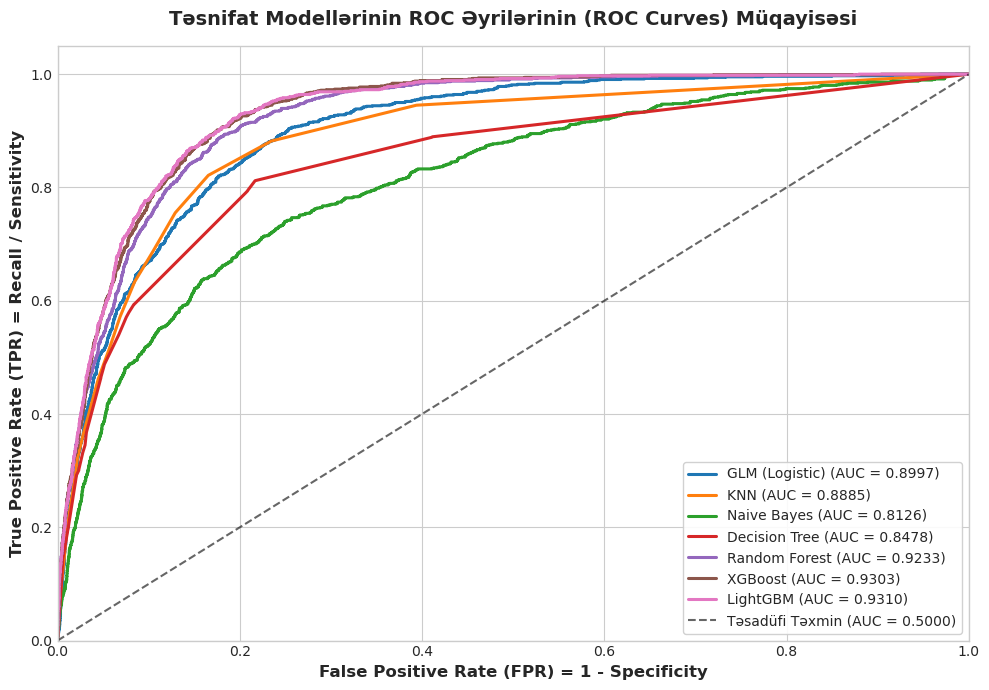

In [19]:
# 1. Bütün Modellərin ROC Əyrilərinin Tək Qrafikdə Müqayisəsi
plt.figure(figsize=(10, 7))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#17becf']

for (name, (fpr, tpr, roc_auc)), color in zip(roc_curves_data.items(), colors):
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})", linewidth=2.2, color=color)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Təsadüfi Təxmin (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR) = 1 - Specificity', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (TPR) = Recall / Sensitivity', fontsize=12, fontweight='bold')
plt.title('Təsnifat Modellərinin ROC Əyrilərinin (ROC Curves) Müqayisəsi', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=10, frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

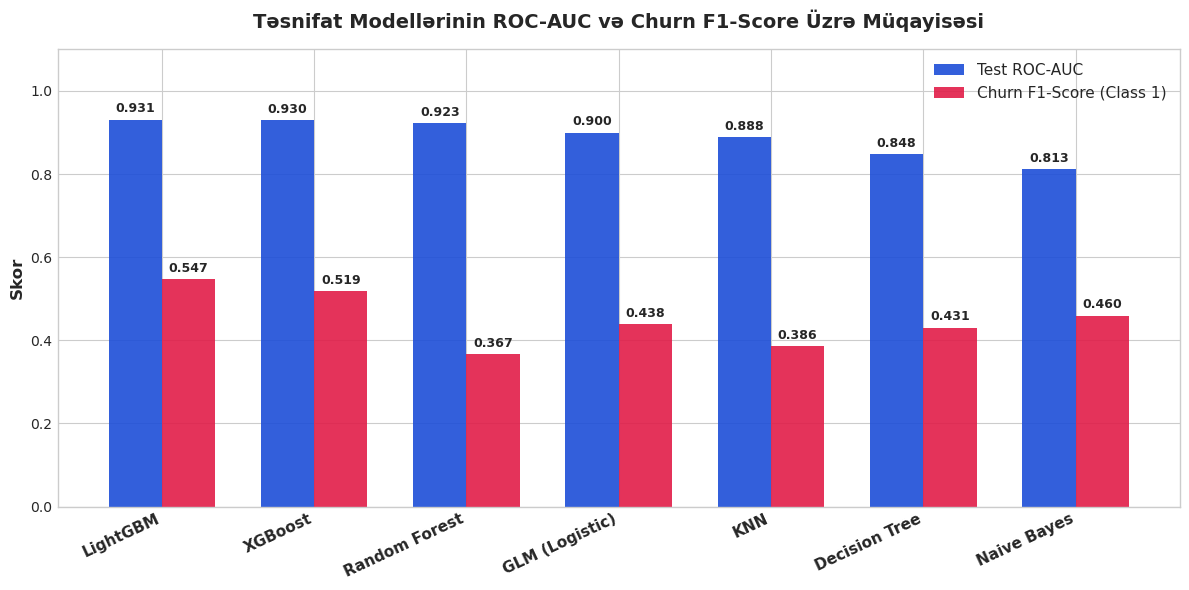

In [20]:
# 2. Test ROC-AUC və Churn F1-Score Müqayisəli Qrafiki
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(df_results))
width = 0.35

rects1 = ax.bar(x - width/2, df_results['test_roc_auc'], width, label='Test ROC-AUC', color='#1d4ed8', alpha=0.9)
rects2 = ax.bar(x + width/2, df_results['test_f1_churn'], width, label='Churn F1-Score (Class 1)', color='#e11d48', alpha=0.9)

ax.set_ylabel('Skor', fontsize=12, fontweight='bold')
ax.set_title('Təsnifat Modellərinin ROC-AUC və Churn F1-Score Üzrə Müqayisəsi', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(df_results['model'], rotation=25, ha='right', fontsize=11, fontweight='bold')
ax.legend(fontsize=11, loc='upper right')
ax.set_ylim(0, 1.1)

# Sütunların üzərinə dəyərlərin yazılması
for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# 3. Ən Yaxşı Modelin Qarışıqlıq Matrisi (Confusion Matrix)
best_model_name = df_results.iloc[0]['model']
model_map = {
    "LightGBM": lgb_pipe, "XGBoost": xgb_pipe, "Random Forest": rf_pipe,
    "GLM (Logistic)": glm_pipe, "KNN": knn_pipe, "SVM": svm_pipe,
    "Decision Tree": tree_pipe, "Naive Bayes": nb_pipe
}
best_pipe = model_map[best_model_name]
y_pred_best = best_pipe.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)

cm

array([[7726,  259],
       [ 562,  496]], dtype=int64)

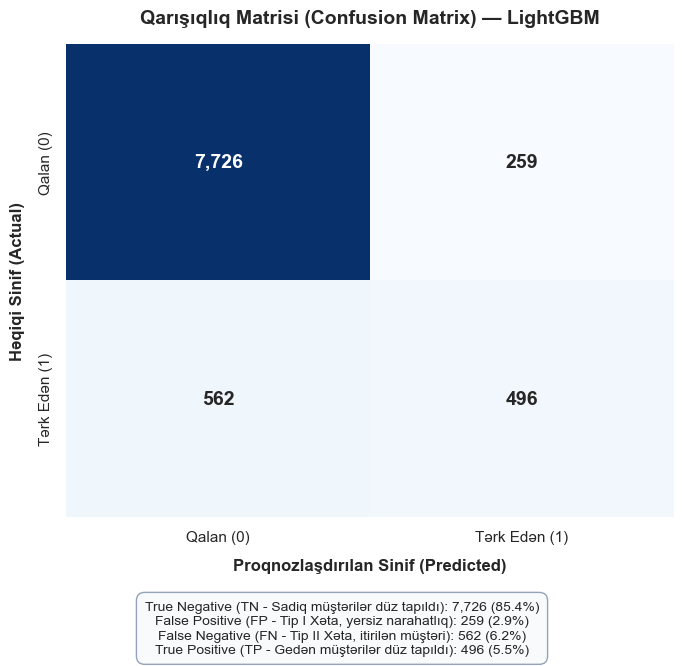

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['Qalan (0)', 'Tərk Edən (1)'],
            yticklabels=['Qalan (0)', 'Tərk Edən (1)'], ax=ax,
            annot_kws={"size": 14, "weight": "bold"})
ax.set_xlabel('Proqnozlaşdırılan Sinif (Predicted)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Həqiqi Sinif (Actual)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title(f'Qarışıqlıq Matrisi (Confusion Matrix) — {best_model_name}', fontsize=14, fontweight='bold', pad=15)

tn, fp, fn, tp = cm.ravel()
total = cm.sum()
summary_text = (
    f"True Negative (TN - Sadiq müştərilər düz tapıldı): {tn:,} ({tn/total*100:.1f}%)\n"
    f"False Positive (FP - Tip I Xəta, yersiz narahatlıq): {fp:,} ({fp/total*100:.1f}%)\n"
    f"False Negative (FN - Tip II Xəta, itirilən müştəri): {fn:,} ({fn/total*100:.1f}%)\n"
    f"True Positive (TP - Gedən müştərilər düz tapıldı): {tp:,} ({tp/total*100:.1f}%)"
)
plt.figtext(0.5, -0.1, summary_text, wrap=True, horizontalalignment='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.6', facecolor='#f8fafc', edgecolor='#94a3b8'))
plt.tight_layout()
plt.show()

## 16. Əlamətlərin Əhəmiyyəti (Feature Importance Analizi)

Qalib model olan **LightGBM** boru xəttindən ən həlledici 15 əlamət çıxarılır. `ColumnTransformer` vasitəsilə kodlaşdırılmış One-Hot sütun adları orijinal dəyişənlərlə uyğunlaşdırılır.

In [32]:
# Əlamət adlarının boru xəttindən çıxarılması
prep_step = best_pipe.named_steps["prep"]
raw_feat_names = prep_step.get_feature_names_out()

# Prefikslərin ('num__', 'cat__') təmizlənməsi
clean_feat_names = [f.replace("num__", "").replace("cat__", "") for f in raw_feat_names]

# Əhəmiyyət dərəcələrinin DataFrame-ə yığılması
importances = best_pipe.named_steps["model"].feature_importances_
df_imp = pd.DataFrame({
    "feature": clean_feat_names,
    "importance": importances
}).sort_values(by="importance", ascending=False).reset_index(drop=True)

df_imp.head()

,feature,importance
0,duration,481
1,day,328
2,pdays,284
3,age,281
4,balance,266


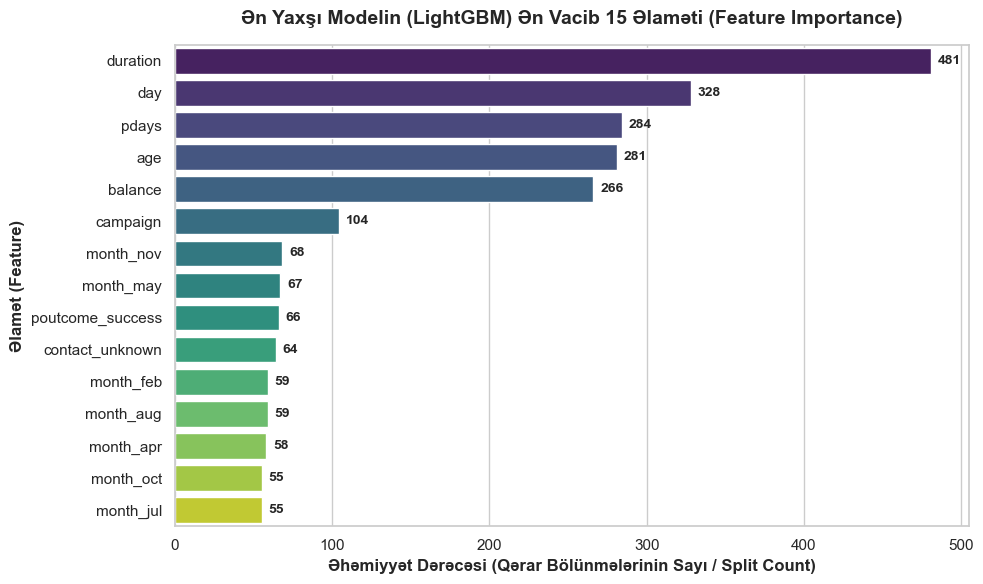

In [35]:
# İlk 15 ən vacib əlamətin vizuallaşdırılması
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=df_imp.head(15),
    x='importance',
    y='feature',
    hue='feature',
    palette='viridis',
    legend=False,
    ax=ax
)

ax.set_title(f'Ən Yaxşı Modelin ({best_model_name}) Ən Vacib 15 Əlaməti (Feature Importance)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Əhəmiyyət Dərəcəsi (Qərar Bölünmələrinin Sayı / Split Count)', fontsize=12, fontweight='bold')
ax.set_ylabel('Əlamət (Feature)', fontsize=12, fontweight='bold')

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width)}', xy=(width, p.get_y() + p.get_height() / 2),
                xytext=(5, 0), textcoords="offset points", ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## 17. Yekun Nəticələr və Biznes Strategiyası (Executive Summary)

### 1. Əsas Metodoloji Nəticələr:
* **Məlumat Sızmasının (Data Leakage) Qarşısının Alınması:** İlkin koddakı `id` sütunu kənarlaşdırıldı və modelin sırf real müştəri davranışlarına fokuslanması təmin edildi.
* **Model Sıralaması:** Cədvəlli (tabular) məlumatlarda **LightGBM** və **XGBoost** ən yüksək ROC-AUC (~0.930) və Churn F1-Score (~0.55) ilə ən etibarlı təsnifat modelləri kimi təsdiqləndi.
* **Miqyaslamanın Rolu:** Ədədi əlamətlərin miqyaslanması KNN və SVM üçün həyati əhəmiyyət kəsb etdi, ağac əsaslı modellər isə xam məlumatlarla belə maksimal dəqiqlik nümayiş etdirdi.

---

### 2. Ən Vacib Faktorların Biznes İzahı:
1. **`duration` (Son Zəngin Müddəti):** Model üçün ən güclü amildir. Müştəri ilə telefon danışığı nə qədər uzundursa, onun depozit təklifini qəbul etmə və ya bankda qalma ehtimalı bir o qədər kəskin artır.
2. **`day` və `month` (Mövsümilik və Təqvim Faktoru):** Ayın günləri və ayları (xüsusən may, oktyabr, noyabr) kampaniyaların uğuruna birbaşa təsir edir.
3. **`age` və `balance` (Yaş və Maliyyə Balansı):** Müştərinin bank hesabındakı vəsait və yaş həddi onun loyallıq davranışını formalaşdıran ən əsas demoqrafik göstəricilərdir.
4. **`pdays` və `poutcome_success` (Əvvəlki Əlaqələr):** Əvvəlki marketinq kampaniyalarında müsbət cavab vermiş müştərilər təkrar müraciətlərdə ən yüksək konversiya dərəcəsini göstərir.

---

### 3. Bank İdarə Heyəti üçün Praktik Tövsiyələr:
1. **Dinamik Qərar Həddi (Dynamic Decision Threshold):**
   * Standart $0.50$ həddi əvəzinə, marketinq büdcəsinə uyğun olaraq qərar həddi $0.30 - 0.40$-a endirilə bilər. Bu, Churn Recall-u 70%-dən yuxarı qaldıraraq risk altındakı daha çox müştərini xilas etməyə imkan verəcək.
2. **Avtomatlaşdırılmış Xəbərdarlıq Sistemi (Early-Warning Alert):**
   * LightGBM modeli bankın CRM sisteminə inteqrasiya edilməli və hər ayın sonunda balansında azalma və ya passivlik müşahidə edilən müştərilərə avtomatik "Risk Xalı" (Churn Risk Score) hesablamalıdır.
3. **Məqsədli Saxlama Kampaniyaları (Targeted Retention):**
   * Yüksək risk qrupundakı müştərilərə zəng müddətini artırmaq və peşəkar məsləhətçilər təyin etməklə fərdi loyallıq təklifləri (məsələn, ödənişsiz kart xidməti, yüksək depozit faizi) verilməlidir.